In [165]:
import pandas as pd
import numpy as np
import joblib

data = pd.read_csv("../dataset/fake_job_postings.csv")

data["fraudulent"] = data["fraudulent"].map({
    "f": 0,
    "t": 1
})

print(data["fraudulent"].value_counts())

fraudulent
0    17014
1      866
Name: count, dtype: int64


In [166]:
text_columns = [
    "title",
    "description",
    "requirements",
    "company_profile",
    "benefits"
]

data["combined_text"] = (
    data[text_columns]
    .fillna("")
    .agg(" ".join, axis=1)
)

data["description_length"] = (
    data["description"]
    .fillna("")
    .str.len()
)

data["has_salary"] = (
    data["salary_range"]
    .fillna("")
    .str.strip()
    .ne("")
    .astype(int)
)

categorical_features = [
    "location",
    "employment_type",
    "industry"
]

numerical_features = [
    "description_length",
    "has_salary"
]

X = data[
    ["combined_text"] +
    categorical_features +
    numerical_features
]

y = data["fraudulent"]

In [167]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train:")
print(y_train.value_counts())

print("\nTest:")
print(y_test.value_counts())

Train:
fraudulent
0    13611
1      693
Name: count, dtype: int64

Test:
fraudulent
0    3403
1     173
Name: count, dtype: int64


In [168]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

encoder = OneHotEncoder(
    handle_unknown="ignore"
)

scaler = StandardScaler()

In [170]:
X_train_text = tfidf.fit_transform(
    X_train["combined_text"]
)

X_test_text = tfidf.transform(
    X_test["combined_text"]
)

X_train_cat = encoder.fit_transform(
    X_train[categorical_features]
)

X_test_cat = encoder.transform(
    X_test[categorical_features]
)

X_train_num = scaler.fit_transform(
    X_train[numerical_features]
)

X_test_num = scaler.transform(
    X_test[numerical_features]
)

In [171]:
from scipy.sparse import hstack

X_train_final = hstack([
    X_train_text,
    X_train_cat,
    X_train_num
])

X_test_final = hstack([
    X_test_text,
    X_test_cat,
    X_test_num
])

print("Training shape:", X_train_final.shape)
print("Testing shape:", X_test_final.shape)

Training shape: (14304, 12890)
Testing shape: (3576, 12890)


🤖Model 1 — Logistic Regression

This will be our baseline model.

In [172]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_model.fit(
    X_train_final,
    y_train
)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [173]:
#Prediction
lr_pred = lr_model.predict(X_test_final)

lr_prob = lr_model.predict_proba(
    X_test_final
)[:, 1]

print("Actual:", np.unique(y_test))
print("Predicted:", np.unique(lr_pred))

Actual: [0 1]
Predicted: [0 1]


In [174]:
#Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, lr_pred)

precision = precision_score(
    y_test,
    lr_pred,
    pos_label=1,
    zero_division=0
)

recall = recall_score(
    y_test,
    lr_pred,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_test,
    lr_pred,
    pos_label=1,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    lr_prob
)

print("Logistic Regression")
print("-------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

Logistic Regression
-------------------
Accuracy : 0.9799
Precision: 0.7285
Recall   : 0.9306
F1 Score : 0.8173
ROC-AUC  : 0.9867


In [175]:
results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        lr_pred,
        lr_prob
    )
)

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression    0.9799     0.7285  0.9306    0.8173   0.9867


In [176]:
pd.DataFrame(results)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.979866,0.728507,0.930636,0.817259,0.986732


🤖 Model 2 — Naive Bayes

In [178]:
# Features for Naive Bayes
X_train_nb = hstack([
    X_train_text,
    X_train_cat
])

X_test_nb = hstack([
    X_test_text,
    X_test_cat
])

print("Naive Bayes training shape:", X_train_nb.shape)
print("Naive Bayes testing shape:", X_test_nb.shape)

Naive Bayes training shape: (14304, 12888)
Naive Bayes testing shape: (3576, 12888)


In [180]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(
    X_train_nb,
    y_train
)

print("Naive Bayes trained successfully!")

Naive Bayes trained successfully!


In [181]:
nb_pred = nb_model.predict(X_test_nb)

nb_prob = nb_model.predict_proba(
    X_test_nb
)[:, 1]

print("Actual classes:", np.unique(y_test))
print("Predicted classes:", np.unique(nb_pred))

Actual classes: [0 1]
Predicted classes: [0 1]


In [182]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

nb_accuracy = accuracy_score(y_test, nb_pred)

nb_precision = precision_score(
    y_test,
    nb_pred,
    pos_label=1,
    zero_division=0
)

nb_recall = recall_score(
    y_test,
    nb_pred,
    pos_label=1,
    zero_division=0
)

nb_f1 = f1_score(
    y_test,
    nb_pred,
    pos_label=1,
    zero_division=0
)

nb_roc_auc = roc_auc_score(
    y_test,
    nb_prob
)

print("Naive Bayes")
print("-------------------")
print("Accuracy :", round(nb_accuracy, 4))
print("Precision:", round(nb_precision, 4))
print("Recall   :", round(nb_recall, 4))
print("F1 Score :", round(nb_f1, 4))
print("ROC-AUC  :", round(nb_roc_auc, 4))

Naive Bayes
-------------------
Accuracy : 0.9704
Precision: 0.8454
Recall   : 0.474
F1 Score : 0.6074
ROC-AUC  : 0.9582


🤖 Model 3 — Linear SVM

In [187]:
#Training
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42
)

svm_model.fit(
    X_train_final,
    y_train
)

print("Linear SVM trained successfully!")

Linear SVM trained successfully!


In [188]:
#Prediction
svm_pred = svm_model.predict(X_test_final)

# LinearSVC does not have predict_proba()
svm_score = svm_model.decision_function(X_test_final)

print("Actual classes:", np.unique(y_test))
print("Predicted classes:", np.unique(svm_pred))

Actual classes: [0 1]
Predicted classes: [0 1]


In [189]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

svm_accuracy = accuracy_score(y_test, svm_pred)

svm_precision = precision_score(
    y_test,
    svm_pred,
    pos_label=1,
    zero_division=0
)

svm_recall = recall_score(
    y_test,
    svm_pred,
    pos_label=1,
    zero_division=0
)

svm_f1 = f1_score(
    y_test,
    svm_pred,
    pos_label=1,
    zero_division=0
)

svm_roc_auc = roc_auc_score(
    y_test,
    svm_score
)

print("Linear SVM")
print("-------------------")
print("Accuracy :", round(svm_accuracy, 4))
print("Precision:", round(svm_precision, 4))
print("Recall   :", round(svm_recall, 4))
print("F1 Score :", round(svm_f1, 4))
print("ROC-AUC  :", round(svm_roc_auc, 4))

Linear SVM
-------------------
Accuracy : 0.9905
Precision: 0.9264
Recall   : 0.8728
F1 Score : 0.8988
ROC-AUC  : 0.9897


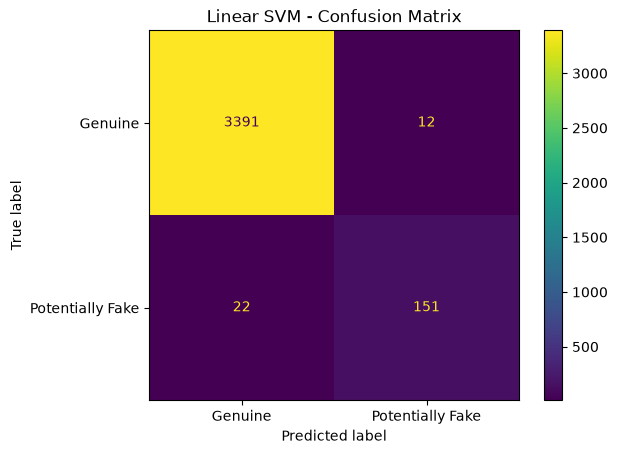

In [190]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, svm_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Genuine", "Potentially Fake"]
)

disp.plot()
plt.title("Linear SVM - Confusion Matrix")
plt.show()

🤖 Model 4 — Random Forest 🌳

In [191]:
#Training
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_final,
    y_train
)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [192]:
rf_pred = rf_model.predict(X_test_final)

rf_prob = rf_model.predict_proba(
    X_test_final
)[:, 1]

print("Actual classes:", np.unique(y_test))
print("Predicted classes:", np.unique(rf_pred))

Actual classes: [0 1]
Predicted classes: [0 1]


In [193]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rf_accuracy = accuracy_score(y_test, rf_pred)

rf_precision = precision_score(
    y_test,
    rf_pred,
    pos_label=1,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_pred,
    pos_label=1,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_pred,
    pos_label=1,
    zero_division=0
)

rf_roc_auc = roc_auc_score(
    y_test,
    rf_prob
)

print("Random Forest")
print("-------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_roc_auc, 4))

Random Forest
-------------------
Accuracy : 0.9824
Precision: 0.9661
Recall   : 0.659
F1 Score : 0.7835
ROC-AUC  : 0.9896


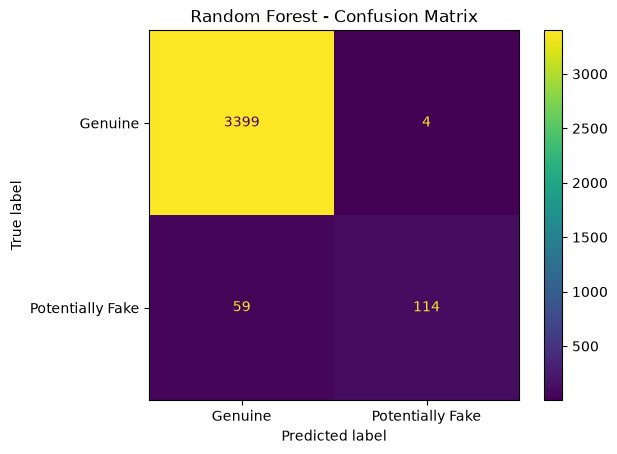

In [194]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Genuine", "Potentially Fake"]
)

disp.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

🤖 Model 5 — XGBoost 🚀

In [195]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_final,
    y_train
)

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [196]:
xgb_pred = xgb_model.predict(X_test_final)

xgb_prob = xgb_model.predict_proba(
    X_test_final
)[:, 1]

print("Actual classes:", np.unique(y_test))
print("Predicted classes:", np.unique(xgb_pred))

Actual classes: [0 1]
Predicted classes: [0 1]


In [197]:
xgb_accuracy = accuracy_score(y_test, xgb_pred)

xgb_precision = precision_score(
    y_test,
    xgb_pred,
    pos_label=1,
    zero_division=0
)

xgb_recall = recall_score(
    y_test,
    xgb_pred,
    pos_label=1,
    zero_division=0
)

xgb_f1 = f1_score(
    y_test,
    xgb_pred,
    pos_label=1,
    zero_division=0
)

xgb_roc_auc = roc_auc_score(
    y_test,
    xgb_prob
)

print("XGBoost")
print("-------------------")
print("Accuracy :", round(xgb_accuracy, 4))
print("Precision:", round(xgb_precision, 4))
print("Recall   :", round(xgb_recall, 4))
print("F1 Score :", round(xgb_f1, 4))
print("ROC-AUC  :", round(xgb_roc_auc, 4))

XGBoost
-------------------
Accuracy : 0.9846
Precision: 0.9758
Recall   : 0.6994
F1 Score : 0.8148
ROC-AUC  : 0.9896


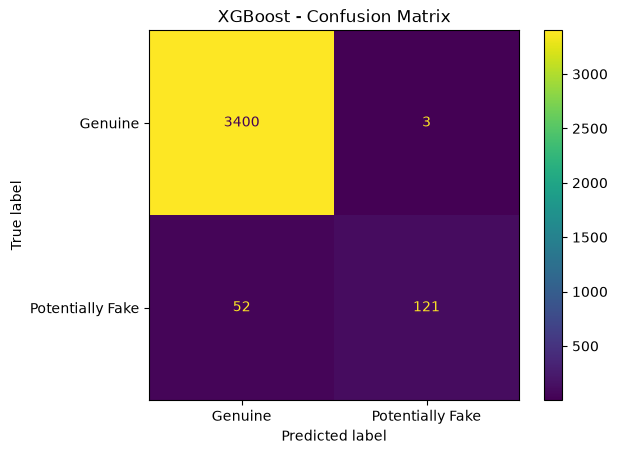

In [198]:
cm = confusion_matrix(y_test, xgb_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Genuine", "Potentially Fake"]
)

disp.plot()
plt.title("XGBoost - Confusion Matrix")
plt.show()

🤖 Compare All Models

In [199]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Linear SVM",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy,
        nb_accuracy,
        svm_accuracy,
        rf_accuracy,
        xgb_accuracy
    ],
    "Precision": [
        precision,
        nb_precision,
        svm_precision,
        rf_precision,
        xgb_precision
    ],
    "Recall": [
        recall,
        nb_recall,
        svm_recall,
        rf_recall,
        xgb_recall
    ],
    "F1 Score": [
        f1,
        nb_f1,
        svm_f1,
        rf_f1,
        xgb_f1
    ],
    "ROC-AUC": [
        roc_auc,
        nb_roc_auc,
        svm_roc_auc,
        rf_roc_auc,
        xgb_roc_auc
    ]
})

results = results.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Linear SVM,0.9905,0.9264,0.8728,0.8988,0.9897
1,Logistic Regression,0.9799,0.7285,0.9306,0.8173,0.9867
2,XGBoost,0.9846,0.9758,0.6994,0.8148,0.9896
3,Random Forest,0.9824,0.9661,0.6590,0.7835,0.9896
4,Naive Bayes,0.9704,0.8454,0.4740,0.6074,0.9582


In [200]:
best_model_name = results.loc[0, "Model"]

print("Best Model:", best_model_name)
print("\nBest Model Performance:")
print(results.iloc[0])

Best Model: Linear SVM

Best Model Performance:
Model        Linear SVM
Accuracy       0.990492
Precision       0.92638
Recall         0.872832
F1 Score        0.89881
ROC-AUC        0.989723
Name: 0, dtype: object


In [201]:
results.to_csv(
    "../models/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


Visual Model Comparison 📊

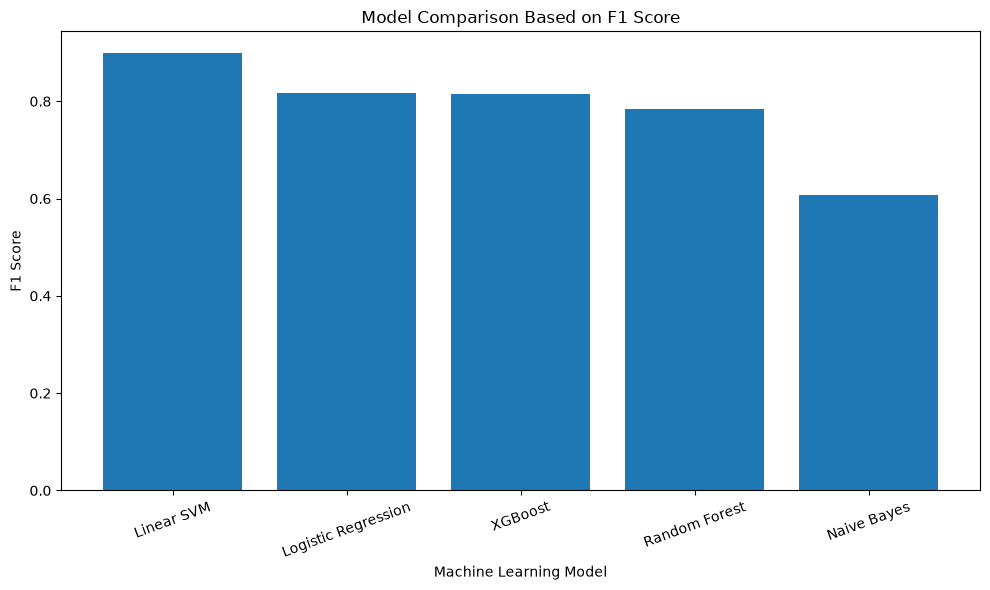

In [202]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    results["Model"],
    results["F1 Score"]
)

plt.xlabel("Machine Learning Model")
plt.ylabel("F1 Score")
plt.title("Model Comparison Based on F1 Score")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Save the Best Model + Preprocessors

In [203]:
import joblib
import os

# Make sure models directory exists
os.makedirs("../models", exist_ok=True)

# Save best ML model
joblib.dump(
    svm_model,
    "../models/fake_job_svm_model.pkl"
)

# Save preprocessing objects
joblib.dump(
    tfidf,
    "../models/tfidf_vectorizer.pkl"
)

joblib.dump(
    encoder,
    "../models/onehot_encoder.pkl"
)

joblib.dump(
    scaler,
    "../models/standard_scaler.pkl"
)

print("All model files saved successfully!")

All model files saved successfully!


Verifies The Files

In [204]:
import os

model_files = os.listdir("../models")

for file in model_files:
    print(file)

fake_job_svm_model.pkl
model_comparison.csv
onehot_encoder.pkl
standard_scaler.pkl
tfidf_vectorizer.pkl


Generate the Final Classification Report

In [205]:
from sklearn.metrics import classification_report

print("Linear SVM Classification Report")
print("---------------------------------")

print(
    classification_report(
        y_test,
        svm_pred,
        target_names=[
            "Genuine",
            "Potentially Fake"
        ],
        digits=4
    )
)

Linear SVM Classification Report
---------------------------------
                  precision    recall  f1-score   support

         Genuine     0.9936    0.9965    0.9950      3403
Potentially Fake     0.9264    0.8728    0.8988       173

        accuracy                         0.9905      3576
       macro avg     0.9600    0.9347    0.9469      3576
    weighted avg     0.9903    0.9905    0.9904      3576



In [206]:
cm = confusion_matrix(y_test, svm_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[3391   12]
 [  22  151]]


Module 4 — Explainable AI (SHAP)

Step 1 — Import SHAP

In [207]:
import shap
import numpy as np
import pandas as pd

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


Step 2 — Create Feature Names

Our final SVM input contains:

TF-IDF text features
One-hot categorical features
Numerical features

In [208]:
# TF-IDF feature names
tfidf_features = tfidf.get_feature_names_out()

# One-hot encoded feature names
cat_features = encoder.get_feature_names_out(
    categorical_features
)

# Numerical feature names
num_features = np.array(
    numerical_features
)

# Combine all feature names
feature_names = np.concatenate([
    tfidf_features,
    cat_features,
    num_features
])

print("Total features:", len(feature_names))
print("First 20 features:")
print(feature_names[:20])

Total features: 12890
First 20 features:
['00' '000' '000 per' '0in' '0in 4pt' '0in mso' '0pt' '10' '10 years'
 '100' '1000' '11' '12' '12 month' '12 months' '13' '14' '15' '150' '1500']


Step 3 — Create SHAP Explainer

In [209]:
explainer = shap.LinearExplainer(
    svm_model,
    X_train_final
)

print("SHAP explainer created successfully!")

Background dataset has 14304 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=14304 when initializing the masker.


SHAP explainer created successfully!


Step 4 — Select a Few Test Jobs

In [211]:
# Convert sparse matrices to CSR format
X_train_final = X_train_final.tocsr()
X_test_final = X_test_final.tocsr()

# Now select the first 5 test jobs
X_sample = X_test_final[:5]

print("Sample shape:", X_sample.shape)

shap_values = explainer.shap_values(
    X_sample
)

print("SHAP values generated successfully!")
print("SHAP shape:", shap_values.shape)

Sample shape: (5, 12890)
SHAP values generated successfully!
SHAP shape: (5, 12890)


Step 5 — Create SHAP Feature Importance Plot

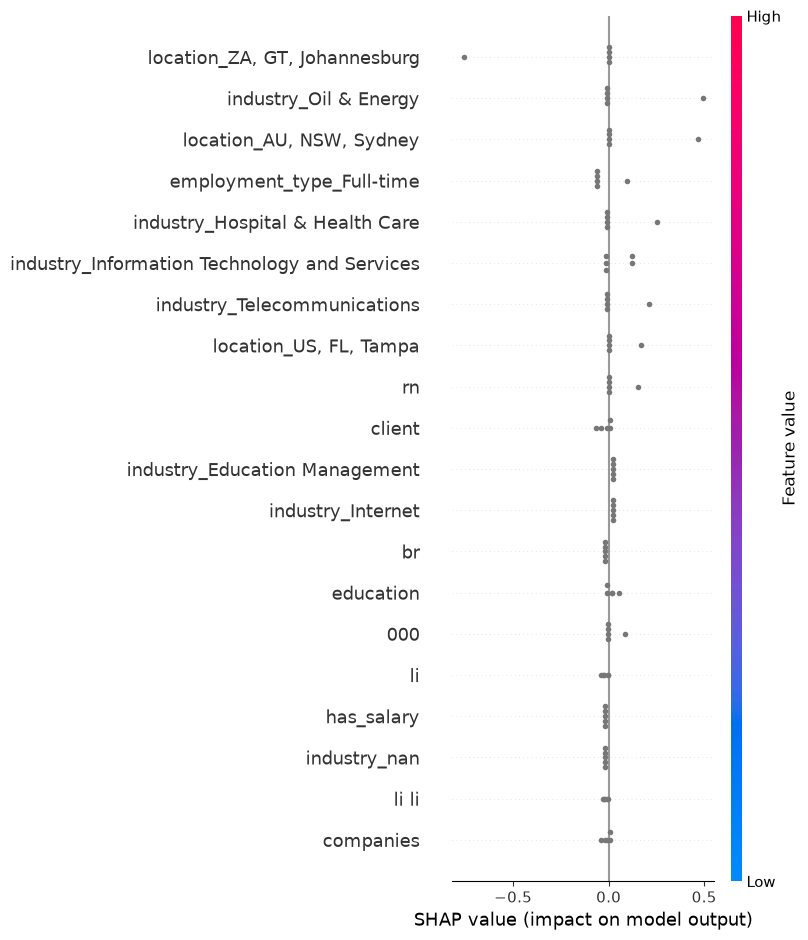

In [212]:
shap.summary_plot(
    shap_values,
    X_sample,
    feature_names=feature_names,
    max_display=20
)

Step 6 — Explain One Specific Job

In [213]:
job_index = 0

job_shap_values = shap_values[job_index]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "SHAP Value": job_shap_values
})

feature_importance["Absolute Impact"] = (
    feature_importance["SHAP Value"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute Impact",
    ascending=False
)

feature_importance.head(15)

,Feature,SHAP Value,Absolute Impact
12808,industry_Hospital & Health Care,0.255610,0.255610
7355,rn,0.156097,0.156097
1,000,0.084748,0.084748
4046,hospital,0.081529,0.081529
84,50,-0.066886,0.066886
1869,client,-0.066517,0.066517
1873,client is,-0.060780,0.060780
1771,center,0.060744,0.060744
12753,employment_type_Full-time,-0.058839,0.058839
2856,education,0.055190,0.055190


Step 7 — Display the Top Positive/Negative Factors

In [214]:
top_features = feature_importance.head(10)[
    ["Feature", "SHAP Value"]
]

print(top_features.to_string(index=False))

                        Feature  SHAP Value
industry_Hospital & Health Care    0.255610
                             rn    0.156097
                            000    0.084748
                       hospital    0.081529
                             50   -0.066886
                         client   -0.066517
                      client is   -0.060780
                         center    0.060744
      employment_type_Full-time   -0.058839
                      education    0.055190


Step 8 — Get the Model's Prediction

In [215]:
job_prediction = svm_model.predict(
    X_test_final[job_index]
)[0]

if job_prediction == 1:
    prediction_label = "Potentially Fake"
else:
    prediction_label = "Genuine"

print("Prediction:", prediction_label)

Prediction: Genuine


Step 13 — Top Positive & Negative Factors

In [216]:
# Explain the first test job
job_index = 0

job_shap_values = shap_values[job_index]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "SHAP Value": job_shap_values
})

# Strongest factors overall
feature_importance["Absolute Impact"] = (
    feature_importance["SHAP Value"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute Impact",
    ascending=False
)

print("Top 15 influential features:")
print(
    feature_importance[
        ["Feature", "SHAP Value"]
    ].head(15).to_string(index=False)
)

Top 15 influential features:
                        Feature  SHAP Value
industry_Hospital & Health Care    0.255610
                             rn    0.156097
                            000    0.084748
                       hospital    0.081529
                             50   -0.066886
                         client   -0.066517
                      client is   -0.060780
                         center    0.060744
      employment_type_Full-time   -0.058839
                      education    0.055190
                     relocation    0.048226
                     healthcare   -0.045566
                           sign   -0.045501
                        medical   -0.044257
                             li   -0.040305


Step 14 — Separate Fake & Genuine Factors

In [217]:
positive_factors = feature_importance[
    feature_importance["SHAP Value"] > 0
].head(10)

negative_factors = feature_importance[
    feature_importance["SHAP Value"] < 0
].head(10)

print("Factors pushing toward Potentially Fake:")
print(
    positive_factors[
        ["Feature", "SHAP Value"]
    ].to_string(index=False)
)

print("\nFactors pushing toward Genuine:")
print(
    negative_factors[
        ["Feature", "SHAP Value"]
    ].to_string(index=False)
)

Factors pushing toward Potentially Fake:
                        Feature  SHAP Value
industry_Hospital & Health Care    0.255610
                             rn    0.156097
                            000    0.084748
                       hospital    0.081529
                         center    0.060744
                      education    0.055190
                     relocation    0.048226
                          urban    0.037943
                         reward    0.036143
                            per    0.035612

Factors pushing toward Genuine:
                  Feature  SHAP Value
                       50   -0.066886
                   client   -0.066517
                client is   -0.060780
employment_type_Full-time   -0.058839
               healthcare   -0.045566
                     sign   -0.045501
                  medical   -0.044257
                       li   -0.040305
               our client   -0.038162
                   50 000   -0.035223


Step 15 — Create a Reusable XAI Function

In [218]:
def explain_job(job_index, top_n=10):
    
    # Get SHAP values for selected job
    job_shap_values = shap_values[job_index]

    explanation = pd.DataFrame({
        "feature": feature_names,
        "shap_value": job_shap_values
    })

    explanation["impact"] = explanation["shap_value"].abs()

    # Sort by strongest influence
    explanation = explanation.sort_values(
        by="impact",
        ascending=False
    )

    top = explanation.head(top_n)

    return top[
        ["feature", "shap_value"]
    ]

In [219]:
explanation = explain_job(
    job_index=0,
    top_n=10
)

print(explanation.to_string(index=False))

                        feature  shap_value
industry_Hospital & Health Care    0.255610
                             rn    0.156097
                            000    0.084748
                       hospital    0.081529
                             50   -0.066886
                         client   -0.066517
                      client is   -0.060780
                         center    0.060744
      employment_type_Full-time   -0.058839
                      education    0.055190


Step 16 — Get the Prediction + Explanation Together

In [220]:
def get_prediction_explanation(job_index, top_n=10):
    
    # Prediction
    prediction = svm_model.predict(
        X_test_final[job_index]
    )[0]

    # Convert prediction to label
    if prediction == 1:
        label = "Potentially Fake"
    else:
        label = "Genuine"

    # SHAP explanation
    job_shap_values = shap_values[job_index]

    explanation = pd.DataFrame({
        "feature": feature_names,
        "shap_value": job_shap_values
    })

    explanation["impact"] = (
        explanation["shap_value"].abs()
    )

    explanation = explanation.sort_values(
        by="impact",
        ascending=False
    ).head(top_n)

    return {
        "prediction": label,
        "prediction_value": int(prediction),
        "explanation": explanation[
            ["feature", "shap_value"]
        ].to_dict("records")
    }

In [221]:
result = get_prediction_explanation(
    job_index=0,
    top_n=10
)

result

{'prediction': 'Genuine',
 'prediction_value': 0,
 'explanation': [{'feature': 'industry_Hospital & Health Care',
   'shap_value': 0.2556098400141098},
  {'feature': 'rn', 'shap_value': 0.1560968967644423},
  {'feature': '000', 'shap_value': 0.08474836511672815},
  {'feature': 'hospital', 'shap_value': 0.08152910491731748},
  {'feature': '50', 'shap_value': -0.06688605200141484},
  {'feature': 'client', 'shap_value': -0.06651691574115919},
  {'feature': 'client is', 'shap_value': -0.06078039583959671},
  {'feature': 'center', 'shap_value': 0.06074420248739336},
  {'feature': 'employment_type_Full-time', 'shap_value': -0.05883879603169525},
  {'feature': 'education', 'shap_value': 0.055190364994815444}]}

In [222]:
# Save a small representative SHAP background dataset
shap_background = X_train_final[:1000].tocsr()

from scipy.sparse import save_npz

save_npz(
    "../models/shap_background.npz",
    shap_background
)

print("SHAP background dataset saved successfully!")

SHAP background dataset saved successfully!
